In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')
import altair as alt #pacote para outros tipos de gráficos

## AA
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import cut_tree

# Exemplo simples: 6 pessoas (idade, renda)

In [2]:
dados=pd.DataFrame({'renda': [9.6,8.4,2.4,18.2,3.9,6.4],
                    'idade': [28, 31, 42, 38, 25, 41]})
dados

,renda,idade
0,9.6,28
1,8.4,31
2,2.4,42
3,18.2,38
4,3.9,25
5,6.4,41


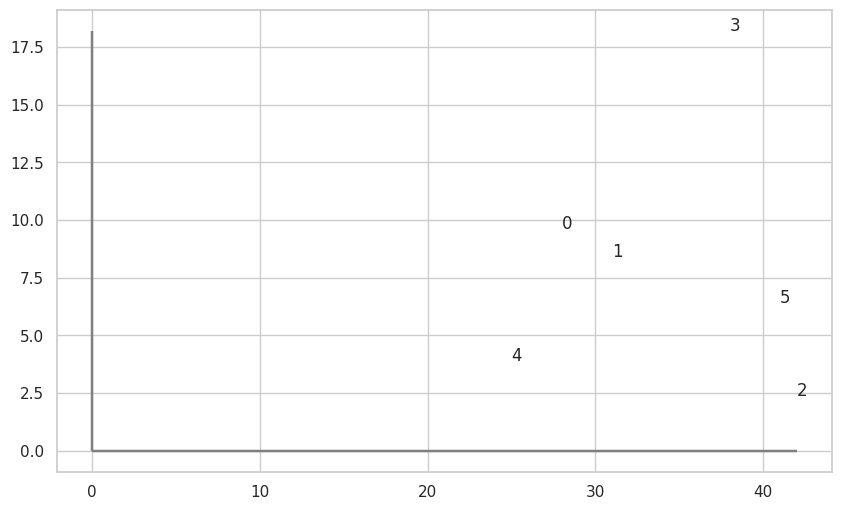

In [3]:
#diagrama de dispersão das variáveis originais
fig, ax = plt.subplots()
fig.set_size_inches(10,6)
ax.scatter(dados.idade,dados.renda,s=0)
for i, txt in enumerate (dados.index):
  ax.annotate(txt, (dados.idade[i], dados.renda[i]))
  plt.hlines(0,0,dados.idade.max(),color='gray')
  plt.vlines(0,0,dados.renda.max(),color='gray');

# Análise de agrupamento

In [4]:
X= dados

Se outro método de agrupamento for escolhido, basta alterar o parâmetro 'method' na função linkage na célula abaixo:

In [5]:
Z=linkage(X,method='single')
# method='single' (vizinho + próximo)
# 'complete''(vizinho + distante)
# 'average' (distância média)
# 'weighted' (also caled WPGMA)
# 'centroid'
# 'median'
# 'ward''

In [6]:
# distâncias
Z

array([[ 0.        ,  1.        ,  3.23109888,  2.        ],
       [ 2.        ,  5.        ,  4.12310563,  2.        ],
       [ 4.        ,  6.        ,  6.44127317,  3.        ],
       [ 7.        ,  8.        , 10.19803903,  5.        ],
       [ 3.        ,  9.        , 12.04325537,  6.        ]])

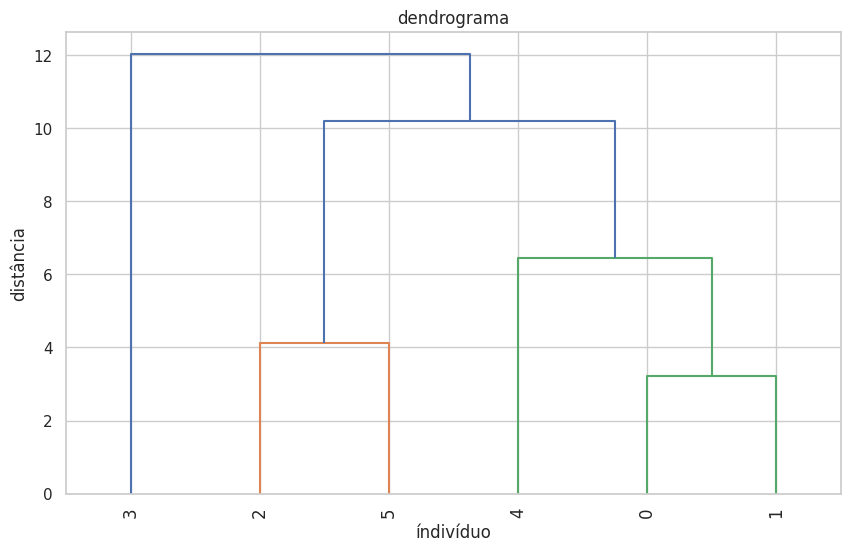

In [7]:
# obter o dendrograma de forma mais automática - função dendrogram
plt.figure(figsize=(10,6))
plt.title('dendrograma')
plt.xlabel('índivíduo')
plt.ylabel('distância')
dendrogram(
    Z,
    leaf_rotation=90., #rotação do eixo
    leaf_font_size=12., #rotação da fonte
)
plt.show()

In [8]:
# definir a distância de corte baseado no dendrograma
max_d=8

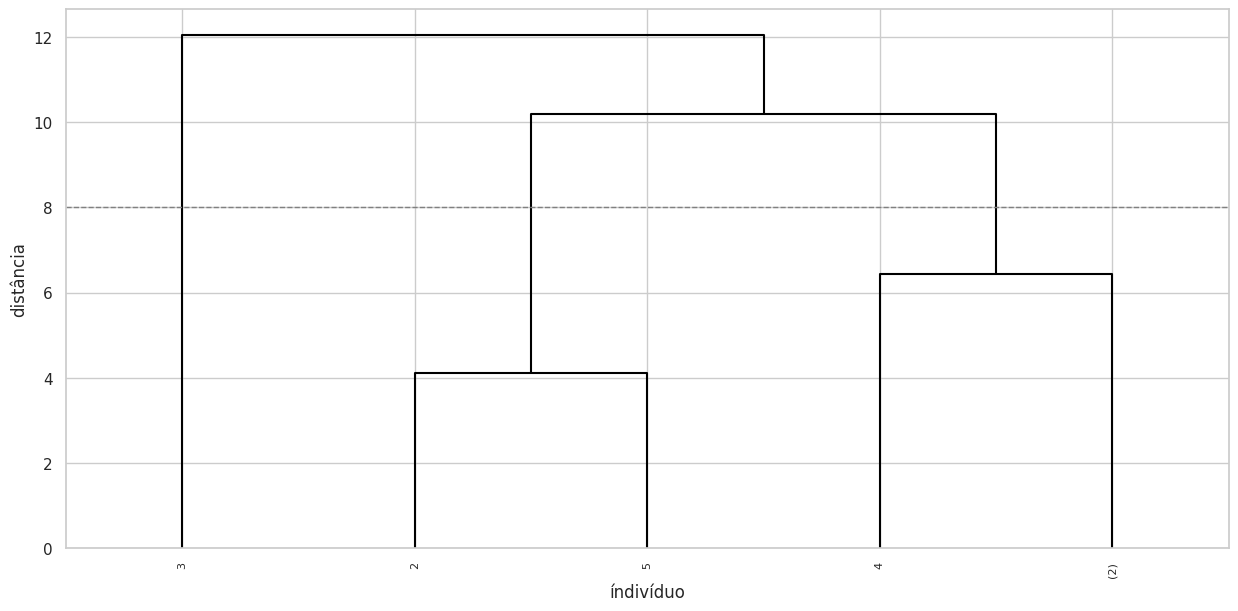

In [9]:
# dendrograma com mais opções
# mostra o ponto de corte na distância max_d
fig, ax=plt.subplots(figsize=(15,7))
ax = dendrogram(
    Z,
    truncate_mode='lastp', #mostrar apenas os p últimos grupos formados
    p=5, # quantos passos mostrar
    show_leaf_counts=True, # mostrar quantas observações há em cada grupo entre parênteses
    leaf_rotation=90., #rotação
    leaf_font_size=8., #tamanho da fonte
    labels=dados.index, #rótulos do eixo x
    show_contracted=True, #to get a distribution impression in trucated branches.
    above_threshold_color='black',
    color_threshold=0.1, #para que todas as linhas sejam da mesma cor
    # color_threshold=max_d, # para que os grupos fiquem com cores diferentes
)
plt.axhline(y=max_d,c='grey',lw=1,linestyle='dashed')
plt.xlabel('índivíduo')
plt.ylabel('distância');

In [10]:
grupos=cut_tree(Z,height=max_d)

In [11]:
# incluir no dataframe de dados as informações sobre a qual grupo cada observação pertence
dados['grupo']=grupos
dados

,renda,idade,grupo
0,9.6,28,0
1,8.4,31,0
2,2.4,42,1
3,18.2,38,2
4,3.9,25,0
5,6.4,41,1


In [12]:
# média dos grupos - todas as variáveis
# inclusive as não utilizadas para agrupar
dados.groupby('grupo').mean()

,renda,idade
grupo,,
0,7.3,28.0
1,4.4,41.5
2,18.2,38.0


In [13]:
# mediana das variáveis para cada grupo
dados.groupby('grupo').median()

,renda,idade
grupo,,
0,8.4,28.0
1,4.4,41.5
2,18.2,38.0


In [14]:
# desvio padrão
dados.groupby('grupo').std()

,renda,idade
grupo,,
0,3.004996,3.000000
1,2.828427,0.707107
2,NaN,NaN


# As observações de cada grupo

In [15]:
grupo0=dados.query('grupo==0').index
list(grupo0)

[0, 1, 4]

In [16]:
grupo1=dados.query('grupo==1').index
list(grupo1)

[2, 5]

In [17]:
grupo2=dados.query('grupo==2').index
list(grupo2)

[3]